In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

In [ ]:
# Original dataset has 20 rows

In [5]:
X = np.load(r"initial_data\function_6\initial_inputs.npy")
Y = np.load(r"initial_data\function_6\initial_outputs.npy")
df = pd.DataFrame({
    'x1': X[:,0],
    'x2': X[:,1],
    'x3': X[:,2],
    'x4': X[:,3],
    'x5': X[:,4],
    'y': Y
})
df.index = df.index+1
df

,x1,x2,x3,x4,x5,y
1,0.728186,0.154693,0.732552,0.693997,0.056401,-0.714265
2,0.242384,0.844100,0.577809,0.679021,0.501953,-1.209955
3,0.729523,0.748106,0.679775,0.356552,0.671054,-1.672200
4,0.770620,0.114404,0.046780,0.648324,0.273549,-1.536058
5,0.618812,0.331802,0.187288,0.756238,0.328835,-0.829237
6,0.784958,0.910682,0.708120,0.959225,0.004911,-1.247049
7,0.145111,0.896685,0.896322,0.726272,0.236272,-1.233786
8,0.945069,0.288459,0.978806,0.961656,0.598016,-1.694343
9,0.125720,0.862725,0.028544,0.246605,0.751206,-2.571170
10,0.757594,0.355831,0.016523,0.434207,0.112433,-1.309116


In [6]:
print(f'Best output value so far:\n {max(Y)}')
print(f'Corresponding x values:\n {X[np.argmax(Y)]}')
print(f'Best query output: \n Query {np.argmax(Y[20:])+1}: {max(Y[20:])}')
print(f'Improvement over last:\n {max(Y)} - {max(Y[:(len(Y)-1)])} = {max(Y)-max(Y[:(len(Y)-1)])}')

Best output value so far:
 -0.0416323795364657
Corresponding x values:
 [0.379808 0.287508 0.660125 0.776426 0.078124]
Best query output: 
 Query 12: -0.0416323795364657
Improvement over last:
 -0.0416323795364657 - -0.10251296755610372 = 0.06088058801963801


In [19]:
kernel = ConstantKernel(1.0) * RBF(length_scale=0.2)
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=20,
    random_state = 42
)

gp.fit(X, Y)

candidate_points = np.random.rand(10000,5)

mu, sigma = gp.predict(candidate_points, return_std=True)

best_y = np.max(Y)
xi = 0

improvement = mu - best_y - xi

Z = np.zeros_like(mu)
mask = sigma > 0
Z[mask] = improvement[mask] / sigma[mask]

EI = np.zeros_like(mu)
EI[mask] = (
    improvement[mask] * norm.cdf(Z[mask])
    + sigma[mask] * norm.pdf(Z[mask])
)

next_point = candidate_points[np.argmax(EI)]

print("Next point:", np.round(next_point, 6))

mean, std = gp.predict(next_point.reshape(-1,5), return_std=True)
print(f'Predicted mean: {mean}')
print(f'Predicted std: {std}')

Next point: [0.345443 0.199956 0.647909 0.730809 0.022095]
Predicted mean: [-0.08603309]
Predicted std: [0.08249213]


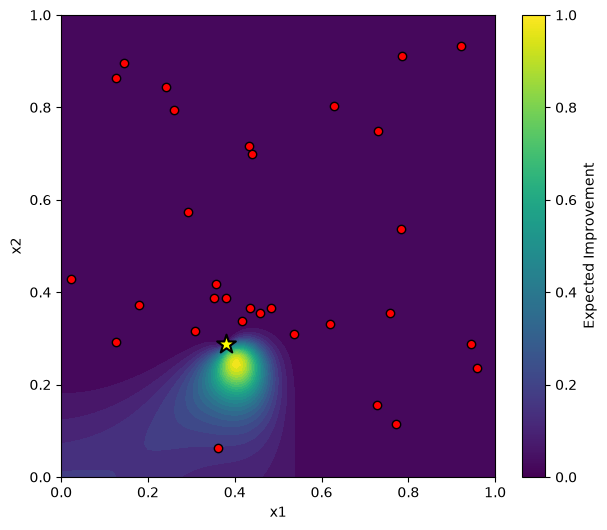

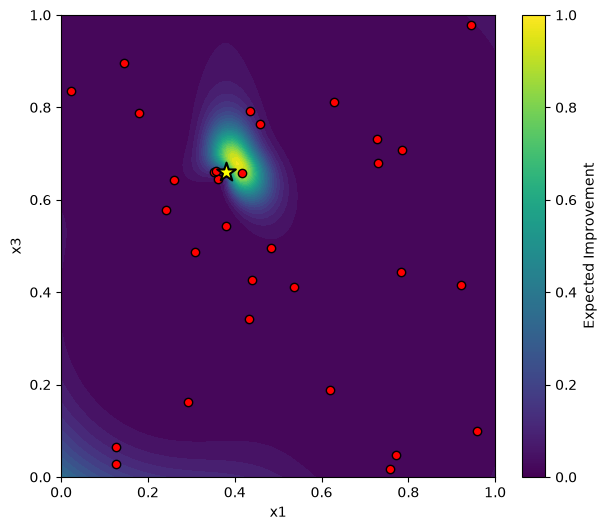

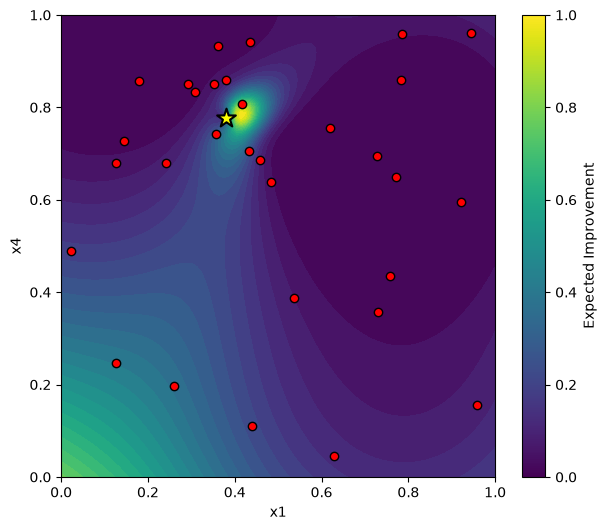

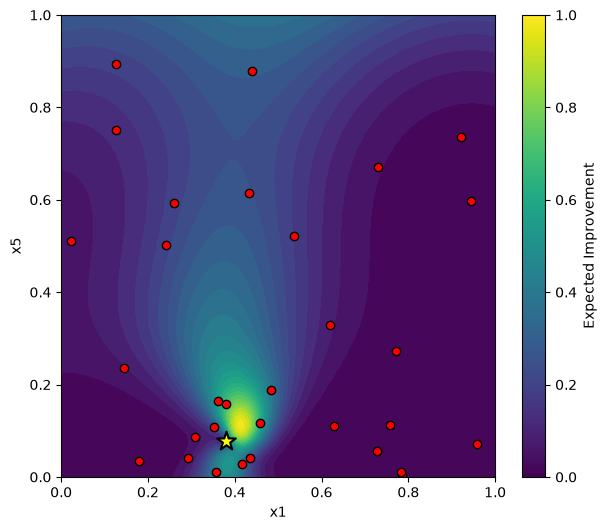

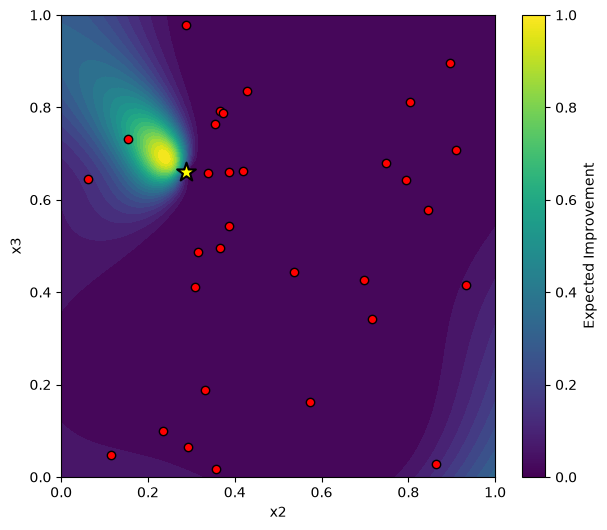

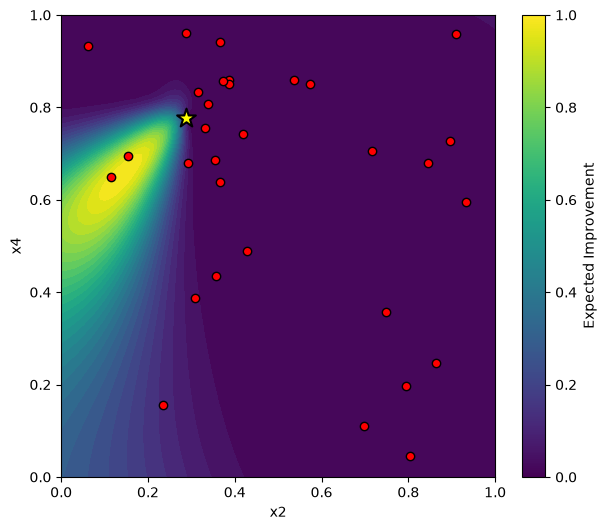

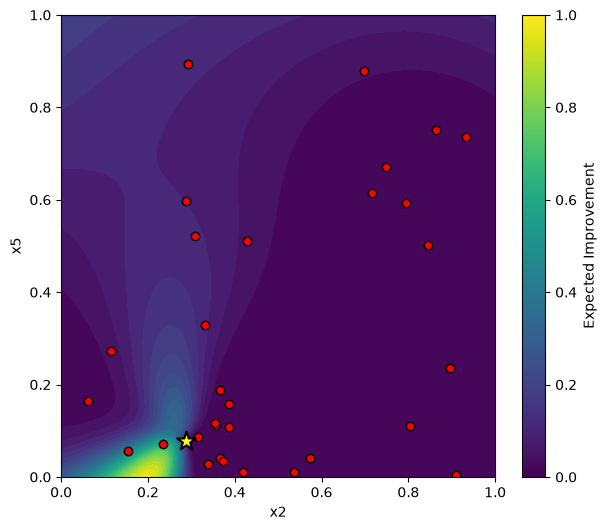

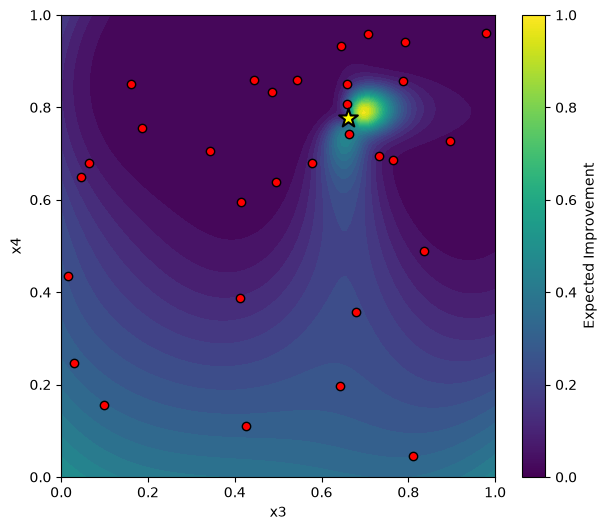

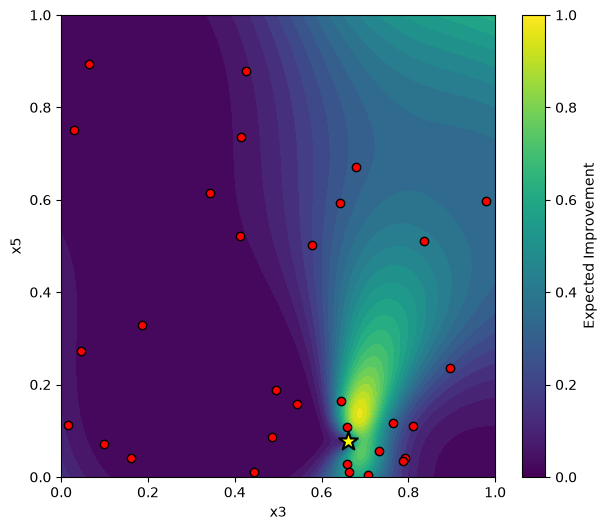

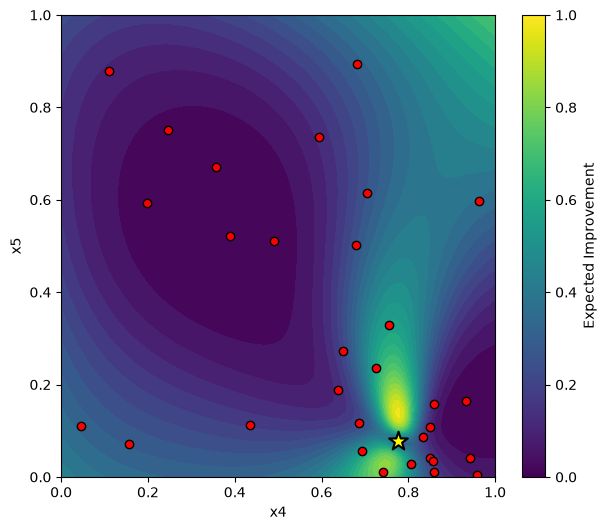

In [14]:
def plot_EI_slice(gp, X, Y, dim1=0, dim2=1, resolution=100, xi=0):
    """
    Plot a 2D slice of the Expected Improvement acquisition function.

    Parameters
    ----------
    gp : fitted GaussianProcessRegressor
    X : observed inputs (n_samples, n_features)
    Y : observed outputs
    dim1 : first variable to plot
    dim2 : second variable to plot
    """

    best_point = X[np.argmax(Y)].copy()

    x = np.linspace(0, 1, resolution)
    y = np.linspace(0, 1, resolution)

    xx, yy = np.meshgrid(x, y)

    grid = np.tile(best_point, (xx.size, 1))

    grid[:, dim1] = xx.ravel()
    grid[:, dim2] = yy.ravel()

    mu, sigma = gp.predict(grid, return_std=True)

    best_y = np.max(Y)

    improvement = mu - best_y - xi

    EI = np.zeros_like(mu)

    mask = sigma > 0

    Z = np.zeros_like(mu)
    Z[mask] = improvement[mask] / sigma[mask]

    EI[mask] = (
        improvement[mask] * norm.cdf(Z[mask])
        + sigma[mask] * norm.pdf(Z[mask])
    )

    plt.figure(figsize=(7,6))

    plt.contourf(xx, yy, EI.reshape(xx.shape), levels=30, cmap="viridis")

    plt.scatter(
        X[:, dim1],
        X[:, dim2],
        c="red",
        edgecolor="black"
    )

    plt.scatter(
    best_point[dim1],
    best_point[dim2],
    c="yellow",
    edgecolor="black",
    s=200,
    marker="*",
    linewidth=1.5,
    label="Current best"
    )

    plt.xlabel(f"x{dim1+1}")
    plt.ylabel(f"x{dim2+1}")

    plt.colorbar(label="Expected Improvement")

    plt.show()

plot_EI_slice(gp, X, Y, dim1=0, dim2=1)
plot_EI_slice(gp, X, Y, dim1=0, dim2=2)
plot_EI_slice(gp, X, Y, dim1=0, dim2=3)
plot_EI_slice(gp, X, Y, dim1=0, dim2=4)
plot_EI_slice(gp, X, Y, dim1=1, dim2=2)
plot_EI_slice(gp, X, Y, dim1=1, dim2=3)
plot_EI_slice(gp, X, Y, dim1=1, dim2=4)
plot_EI_slice(gp, X, Y, dim1=2, dim2=3)
plot_EI_slice(gp, X, Y, dim1=2, dim2=4)
plot_EI_slice(gp, X, Y, dim1=3, dim2=4)

In [ ]:
'''
1st point selected: [0.484288-0.365614-0.495586-0.638325-0.188988]
Output: -0.47661161715197725

2nd point selected: [0.307918-0.315408-0.486389-0.832575-0.087381]
Output: -0.36237982015527576

3rd point selected: [0.292771-0.573582-0.161729-0.850067-0.040025]
Output: -0.9631833036566313

4th point selected: [0.361266-0.062493-0.644017-0.932487-0.164627]
Output: -0.6552935561156785

5th point selected: [0.380838-0.386625-0.543283-0.859584-0.157015]
Output: -0.304145918018451

6th point selected: [0.435185-0.366199-0.791328-0.941928-0.040357]
Output: -0.34432679934348265

7th point selected: [0.351529-0.387787-0.659152-0.850789-0.108894]
Output: -0.17322310827437593

8th point selected: [0.178455-0.373153-0.788531-0.856616-0.034446]
Output: -0.6011948314597265

9th point selected: [0.415955-0.337725-0.658778-0.806730-0.026973]
Output: -0.10251296755610372 

10th point selected: [0.459205-0.355287-0.763756-0.686729-0.117697]
Output: -0.29106254989885094 

11th point selected: [0.356037-0.418426-0.662294-0.742535-0.011229]
Output: -0.2981023785259156 

12th point selected: [0.379808-0.287508-0.660125-0.776426-0.078124]
Output: -0.0416323795364657   ---NEW BEST---

Final point selected: [0.345443-0.199956-0.647909-0.730809-0.022095] --- xi reduced to 0 ---
Output: -0.2979788589107197

In [ ]:
# Updating data with new input-output pairs

# X_query1 = np.array([0.484288,0.365614,0.495586,0.638325,0.188988], dtype=np.float64)
# Y_query1_output = np.array([-0.47661161715197725], dtype=np.float64)
# X_updated = np.vstack((X, X_query1))
# Y_updated = np.append(Y, Y_query1_output)

# X_query2 = np.array([0.307918,0.315408,0.486389,0.832575,0.087381], dtype=np.float64)
# Y_query2_output = np.array([-0.36237982015527576], dtype=np.float64)
# X_updated = np.vstack((X, X_query2))
# Y_updated = np.append(Y, Y_query2_output)

# X_query3 = np.array([0.292771,0.573582,0.161729,0.850067,0.040025], dtype=np.float64)
# Y_query3_output = np.array([-0.9631833036566313], dtype=np.float64)
# X_updated = np.vstack((X, X_query3))
# Y_updated = np.append(Y, Y_query3_output)

# X_query4 = np.array([0.361266,0.062493,0.644017,0.932487,0.164627], dtype=np.float64)
# Y_query4_output = np.array([-0.6552935561156785], dtype=np.float64)
# X_updated = np.vstack((X, X_query4))
# Y_updated = np.append(Y, Y_query4_output)

# X_query5 = np.array([0.380838,0.386625,0.543283,0.859584,0.157015], dtype=np.float64)
# Y_query5_output = np.array([-0.304145918018451], dtype=np.float64)
# X_updated = np.vstack((X, X_query5))
# Y_updated = np.append(Y, Y_query5_output)

# X_query6 = np.array([0.435185,0.366199,0.791328,0.941928,0.040357], dtype=np.float64)
# Y_query6_output = np.array([-0.34432679934348265], dtype=np.float64)
# X_updated = np.vstack((X, X_query6))
# Y_updated = np.append(Y, Y_query6_output)

# X_query7 = np.array([0.351529,0.387787,0.659152,0.850789,0.108894], dtype=np.float64)
# Y_query7_output = np.array([-0.17322310827437593], dtype=np.float64)
# X_updated = np.vstack((X, X_query7))
# Y_updated = np.append(Y, Y_query7_output)

# X_query8 = np.array([0.178455,0.373153,0.788531,0.856616,0.034446], dtype=np.float64)
# Y_query8_output = np.array([-0.6011948314597265], dtype=np.float64)
# X_updated = np.vstack((X, X_query8))
# Y_updated = np.append(Y, Y_query8_output)

# X_query9 = np.array([0.415955,0.337725,0.658778,0.806730,0.026973], dtype=np.float64)
# Y_query9_output = np.array([-0.10251296755610372], dtype=np.float64)
# X_updated = np.vstack((X, X_query9))
# Y_updated = np.append(Y, Y_query9_output)

# X_query10 = np.array([0.459205,0.355287,0.763756,0.686729,0.117697], dtype=np.float64)
# Y_query10_output = np.array([-0.29106254989885094], dtype=np.float64)
# X_updated = np.vstack((X, X_query10))
# Y_updated = np.append(Y, Y_query10_output)

# X_query11 = np.array([0.356037,0.418426,0.662294,0.742535,0.011229], dtype=np.float64)
# Y_query11_output = np.array([-0.2981023785259156], dtype=np.float64)
# X_updated = np.vstack((X, X_query11))
# Y_updated = np.append(Y, Y_query11_output)

# X_query12 = np.array([0.379808,0.287508,0.660125,0.776426,0.078124], dtype=np.float64)
# Y_query12_output = np.array([-0.0416323795364657], dtype=np.float64)
# X_updated = np.vstack((X, X_query12))
# Y_updated = np.append(Y, Y_query12_output)

# X_query13 = np.array([0.345443,0.199956,0.647909,0.730809,0.022095], dtype=np.float64)
# Y_query13_output = np.array([-0.2979788589107197], dtype=np.float64)
# X_updated = np.vstack((X, X_query13))
# Y_updated = np.append(Y, Y_query13_output)

In [ ]:
# Save new data to original files (initial_inputs.npy & initial_outputs.npy)

# np.save(r"initial_data\function_6\initial_inputs.npy", X_updated)
# np.save(r"initial_data\function_6\initial_outputs.npy", Y_updated)